# Fit the full microscope at two voltages

One experiment: **make images → measure them → fit a new microscope → check its predictions and geometry**.

We use **200 and 195 kV**, keeping objective current fixed. CL1, CL3 and the mini form the condenser with the objective pre-field. The objective post-field, IL1–IL3 and PL1 form the projector. Both halves share one geometry across voltages.

For the ray order used here,
$$
\begin{pmatrix}x'\\y'\\\theta_x'\\\theta_y'\\1\end{pmatrix}
=
\underbrace{\begin{pmatrix}
A_{xx}&A_{xy}&B_{xx}&B_{xy}&d_x\\
A_{yx}&A_{yy}&B_{yx}&B_{yy}&d_y\\
C_{xx}&C_{xy}&D_{xx}&D_{xy}&d_{\theta x}\\
C_{yx}&C_{yy}&D_{yx}&D_{yy}&d_{\theta y}\\
0&0&0&0&1
\end{pmatrix}}_{M}
\begin{pmatrix}x\\y\\\theta_x\\\theta_y\\1\end{pmatrix}.
$$
The source-to-detector map is $M_{\rm projector}M_{\rm condenser}$. The specimen changes image intensity at the plane between them; apertures also transmit or reject intensity, so image generation needs more than this matrix product.

**Known inputs:** specimen size/template, detector pixel size and response, both voltages, known aperture diameters, and independently calibrated specimen-plane shifts and tilts **at each voltage**. Lens order and polarity are known; the aperture is assumed between CL3 and the mini. Positions, effective lengths and strengths are fitted. Source position, angle, size and divergence may differ between voltages.

Run top to bottom. Detailed optimization logs and intermediate files stay in `../generated/full_microscope_aligned_apertures/`. Completed steps are reused when their inputs match.

In [1]:
import os
from pathlib import Path
import sys

# The fitting uses double precision on the CPU.
os.environ["JAX_PLATFORMS"] = "cpu"
os.environ["JAX_ENABLE_X64"] = "true"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

HERE = Path.cwd()
if not (HERE / "full_microscope_workflow.py").exists():
    HERE = HERE / "examples" / "microscope_models"
sys.path.insert(0, str(HERE.resolve()))

from full_microscope_workflow import (
    simulate_experiment, measure_projector, fit_projector,
    measure_condenser, fit_microscope, check_full_microscope,
    show_images, show_result,
)

output_directory = HERE.parent / "generated" / "full_microscope_aligned_apertures"
projector_bounds = HERE / "projector_position_priors.json"

## 1. Make the measurements

The hidden microscope generates noisy MAGICAL images and currents. Fitting receives recorded commands, known calibrations and **separate engineering guesses**.

At each voltage we record:

- **Projector:** 11 settings; each has an ordinary image, four tilts ($\pm3$ mrad in $x,y$) and four shifts ($\pm10$ nm in $x,y$).
- **Condenser:** 24 CL1/CL3/mini settings, each imaged through three projector settings **with the aperture retracted**.
- **Apertures:** 39 CL1/CL3 settings, each with transmitted current through **4 and 10 µm holes** and an open reference.

We align each hole once to the same beam at 200 kV and a fixed condenser setting. Each retains its own unknown residual offset during both voltage measurements. We allow **0.2 µm uncertainty per axis**, as an assumed alignment accuracy. No calibrated movement scan is used. The holes share one unknown axial plane.

Total: **342 calibration images and 234 current readings**. New settings supply another 72 images and 48 readings for checking. Adding the 20 µm hole changes these current counts to 312 and 64. This is a working demonstration, not a minimum acquisition.

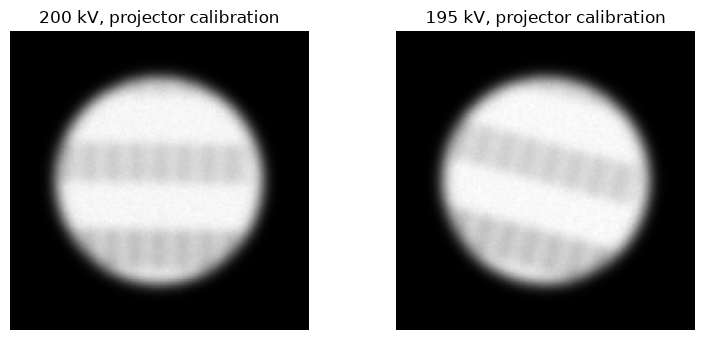

In [2]:
experiment = simulate_experiment(
    output_directory=output_directory,
    voltages_v=(200_000.0, 195_000.0),
    random_seed=24_001,
    aperture_diameters_um=(4.0, 10.0),  # Add 20.0 for three holes.
    centering_sigma_um=0.2,  # Assumed residual alignment uncertainty per axis.
)
show_images(experiment_directory=experiment);

## 2. Fit the projector at both voltages

Calibrated specimen shifts and tilts measure $A$ and $B$:
$$\Delta\mathbf r_{\rm detector}=A\,\Delta\mathbf r_{\rm specimen}+B\,\Delta\boldsymbol\theta_{\rm specimen}.$$
We also measure ordinary-image scale, rotation and blur. Illumination curvature and angular spread are fitted separately at each voltage; parallel illumination is not assumed.

**Input:** measured image changes, engineering guesses and hard bounds. **Output:** shared projector geometry, lens strengths, illumination parameters and covariance.

Eight starts are tried. Convergence alone is insufficient: the measurements must also agree at noise level. No soft position penalties are used.

In [3]:
projector_measurements = measure_projector(
    experiment_directory=experiment,
)
projector = fit_projector(
    measurements_directory=projector_measurements,
    starting_guess_path=HERE / "projector_starting_guess.json",
    bounds_path=projector_bounds,
    number_of_starts=8,
)
accepted = sum(attempt["acceptable"] for attempt in projector["starts"])
print(f"Projector: {accepted}/{len(projector['starts'])} acceptable starts; "
      f"measurement RMS = {projector['best_fit']['residual_rms']:.3f}")

Projector: 7/8 acceptable starts; measurement RMS = 0.954


## 3. Measure the beams and fit the condenser

The fitted projector lets image analysis measure each specimen beam's position, angle, size, curvature and angular spread. **Uncertainty shared through the projector is retained.**

The condenser fit explains those beams, aperture transmissions and the stated alignment accuracy. Geometry is shared; source parameters are independent at each voltage. The fitted beams then update the projector, giving **one complete microscope and its covariance**.

The voltage dependence is fixed by electron momentum:
$$p(V)=\frac{\sqrt{eV(eV+2mc^2)}}{c},\qquad q_i(V,u_i)=g_i u_i\frac{p(V_0)}{p(V)}.$$
Here $u_i$ is recorded relative current and $g_i$ is fitted signed strength. The finite-solenoid matrix supplies focusing and rotation. Objective current stays at $u=1$, with separate fitted pre-field and post-field lengths and strengths.

Eight guesses are tested without soft geometry penalties. The alignment assumption gives a finite-uncertainty constraint on each hole centre. The uncertainty handoff is a local Gaussian approximation; the next step checks it against the original pixels.

In [4]:
specimen_beams = measure_condenser(
    experiment_directory=experiment,
    projector_fit=projector,
    projector_bounds_path=projector_bounds,
)
microscope = fit_microscope(
    beam_measurements_directory=specimen_beams,
    condenser_starting_guess_path=HERE / "microscope_condenser_starting_guess.json",
    projector_bounds_path=projector_bounds,
    number_of_broad_starts=4,  # Plus four structured engineering guesses.
)
fits = microscope["condenser_fit"]
accepted = sum(attempt["acceptable"] for attempt in fits["starts"])
print(f"Condenser: {accepted}/{len(fits['starts'])} acceptable starts; "
      f"measurement RMS = {fits['best_fit']['residual_rms']:.3f}")

Condenser: 6/8 acceptable starts; measurement RMS = 0.951


## 4. Check the complete microscope

Freeze lens, source and aperture parameters. Predict the new images and currents, then compare geometry with the hidden truth. Only new-image dose and background may be adjusted.

RMS near one indicates agreement at the assumed uncertainty level. Positions below are relative to the specimen ($z=0$); intervals are local **one-standard-deviation** uncertainties, including projector uncertainty.

| Lens | True z (mm) | Fitted z ± 1σ (mm) | True length (mm) | Fitted length ± 1σ (mm) |
|---|---:|---:|---:|---:|
| CL1 | -125 | -125.029 ± 0.036 | 5 | 5.00163 ± 0.013 |
| CL3 | -85 | -85.0128 ± 0.045 | 5 | 5.00177 ± 0.00096 |
| Mini | -25 | -25.0001 ± 0.022 | 3 | 3.00405 ± 0.0031 |
| Objective pre-field | -2.5 | -2.50042 ± 0.00066 | 1 | 0.998047 ± 0.042 |
| Objective post-field | 2.3 | 2.30019 ± 0.00024 | 0.4 | 0.400105 ± 9.1e-05 |
| IL1 | 213.52 | 213.539 ± 0.023 | 5 | 4.99984 ± 0.0007 |
| IL2 | 290.48 | 290.5 ± 0.033 | 5 | 5.00037 ± 0.00067 |
| IL3 | 352.98 | 353.004 ± 0.04 | 5 | 5.00051 ± 0.00081 |
| PL1 | 407.98 | 408.01 ± 0.048 | 1 | 0.999999 ± 0.00013 |

| Frozen-model check | RMS in uncertainty units |
|---|---:|
| New full-microscope images | 0.983 |
| New aperture currents | 0.946 |
| New projector settings | 0.909 |

Quantity,Truth,Fit ± 1σ,Range across acceptable starts
detector z mm,718.75,718.79 ± 0.08,—
condenser source z mm,-325,-325.203 ± 0.4,-325.218 to -325.203
condenser aperture z mm,-80,-80.011 ± 0.045,-80.0118 to -80.011
condenser aperture x um,0.215898,0.225318 ± 0.052,0.225314 to 0.242698
condenser aperture y um,-0.503777,-0.498921 ± 0.023,-0.498923 to -0.490675
condenser source z second voltage mm,-325.05,-325.253 ± 0.4,-325.268 to -325.253
condenser aperture 2 x um,0.155747,-0.0845019 ± 0.016,-0.0845029 to 0.15415
condenser aperture 2 y um,-0.0409891,-0.130532 ± 0.01,-0.130532 to -0.0413435


**Some aperture-centre coordinates have several acceptable values.** Their local error bars describe only the selected minimum; inspect the range across starts above.

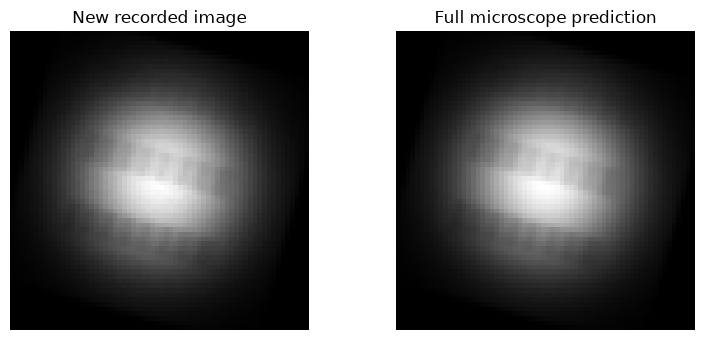

In [5]:
checks = check_full_microscope(
    experiment_directory=experiment,
    microscope=microscope,
    projector_bounds_path=projector_bounds,
)
show_images(experiment_directory=experiment, fitted_predictions=True);
show_result(checks=checks)

Good image predictions do not prove that every coordinate is unique. Circular-aperture currents can leave alternative transverse hole offsets that fit almost equally well. The results therefore show both local uncertainty and the range across acceptable starting guesses.

This model assumes round, coaxial finite solenoids, known voltage and shift/tilt calibration, and repeatable currents and aperture selection. The 0.2 µm alignment accuracy is an assumption to check experimentally. Lens offsets and aberrations are not fitted. Effective field lengths are not metal thicknesses; MAGICAL images describe intensity transport, not coherent diffraction.

The [saved two-versus-three-diameter test](APERTURE_SIZE_COMPARISON.md) uses the same image data for both choices. It found little axial-precision benefit from adding the 20 µm hole.